# Day 13-14: SVM Experiments and Manufacturing Defect Detection

This notebook works through the SVM Python investigation problems: a NumPy linear SVM, C and gamma, kernels, support vectors, feature scaling, rare defects and thresholds, probability calibration, one-class anomaly detection, SVR, approximate kernels, and a batch-aware defect project.

## Setup

All experiments use fixed seeds. Scalers are fitted inside training pipelines or on normal training data only.

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time, pickle
from sklearn.datasets import make_blobs,make_classification,make_moons,make_circles
from sklearn.model_selection import train_test_split,GridSearchCV,StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC,LinearSVC,OneClassSVM,SVR
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,average_precision_score,precision_recall_curve,roc_auc_score,brier_score_loss,log_loss,mean_absolute_error,mean_squared_error
from sklearn.linear_model import LogisticRegression
from sklearn.kernel_approximation import Nystroem
from sklearn.calibration import calibration_curve
from sklearn.base import clone
np.random.seed(42)
def pipe_svm(model,scale=True): return Pipeline([('scale',StandardScaler() if scale else 'passthrough'),('svm',model)])
def boundary(ax,model,X,y,title):
 lo=X.min(0)-.5;hi=X.max(0)+.5;xx,yy=np.meshgrid(np.linspace(lo[0],hi[0],120),np.linspace(lo[1],hi[1],120));g=np.c_[xx.ravel(),yy.ravel()]
 ax.contourf(xx,yy,model.predict(g).reshape(xx.shape),alpha=.2,cmap='coolwarm');ax.scatter(X[:,0],X[:,1],c=y,cmap='coolwarm',s=10);ax.set(title=title)

## 1. Linear SVM from scratch

Implement the stated hinge-loss objective and batch subgradient descent. A point exactly at margin 1 uses zero hinge subgradient. Compare three learning rates with a linear SVC.

best lr 0.01 scratch acc 0.5 SVC acc 1.0 C 0.47619047619047616
inside margin 0 on margin 0


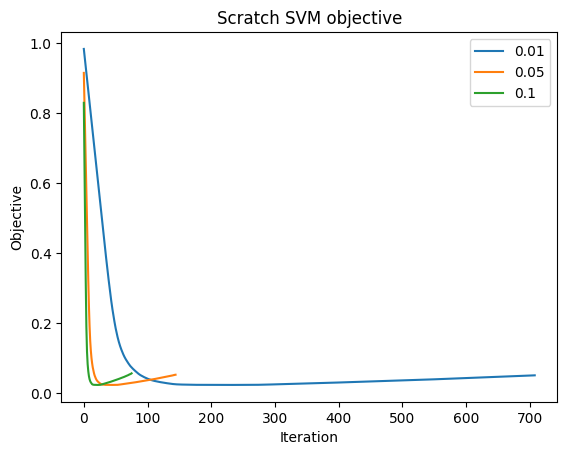

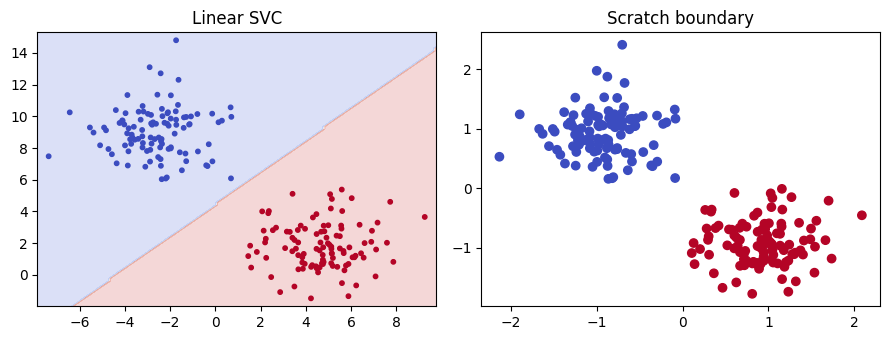

In [5]:
X,y0=make_blobs(n_samples=300,centers=2,cluster_std=1.5,random_state=42);y=np.where(y0==0,-1,1)
Xa,Xt,ya,yt=train_test_split(X,y,test_size=.3,random_state=42,stratify=y);sc=StandardScaler().fit(Xa);A=sc.transform(Xa);T=sc.transform(Xt);lam=.01;n=len(A)
def obj(w,b,A,y):return lam/2*(w@w)+np.maximum(0,1-y*(A@w+b)).mean()
def gd(lr,steps=1000):
 w=np.zeros(2);b=0.;hist=[]
 for _ in range(steps):
  m=y_a*(A@w+b);active=m<1;gw=lam*w-(A[active]*y_a[active,None]).mean(0);gb=-y_a[active].mean();w-=lr*gw;b-=lr*gb;hist.append(obj(w,b,A,y_a))
 return w,b,hist
y_a=ya;runs={lr:gd(lr) for lr in [.01,.05,.1]}
for lr,(_,_,h) in runs.items():plt.plot(h,label=str(lr))
plt.title('Scratch SVM objective');plt.xlabel('Iteration');plt.ylabel('Objective');plt.legend();plt.show()
best=min(runs,key=lambda z:runs[z][2][-1]);w,b,_=runs[best];Cval=1/(n*lam)
lib=Pipeline([('scale',StandardScaler()),('svm',SVC(kernel='linear',C=Cval))]).fit(Xa,ya)
print('best lr',best,'scratch acc',accuracy_score(yt,np.where(T@w+b>=0,1,-1)),'SVC acc',accuracy_score(yt,lib.predict(Xt)),'C',Cval)
m=ya*(A@w+b);print('inside margin',sum(m<1-1e-7),'on margin',sum(np.isclose(m,1,atol=1e-3)))
fig,axs=plt.subplots(1,2,figsize=(9,3.5));boundary(axs[0],Pipeline([('scale',StandardScaler()),('svm',SVC(kernel='linear',C=Cval))]).fit(Xa,ya),Xa,ya,'Linear SVC');axs[1].scatter(A[:,0],A[:,1],c=ya,cmap='coolwarm');xx=np.linspace(A[:,0].min(),A[:,0].max(),100);axs[1].plot(xx,-(w[0]*xx+b)/w[1]);axs[1].set_title('Scratch boundary');plt.tight_layout();plt.show()

## 2. Effect of C

Compare train/validation accuracy, margin width, support-vector count, margin violations, and hinge loss. Choose C on validation data, then evaluate on test data.

          train acc  val acc  margin width  SVs  violations  hinge loss
C                                                                      
0.001         0.507     0.51        11.941  296         296     267.947
0.010         0.767     0.77         2.483  245         244     179.103
0.100         0.790     0.85         1.461  176         174     156.505
1.000         0.800     0.84         1.172  158         156     154.211
10.000        0.800     0.84         1.128  156         155     154.171
100.000       0.800     0.84         1.128  156         156     154.172
1000.000      0.800     0.84         1.128  156         156     154.172
selected C 0.1 test accuracy 0.77


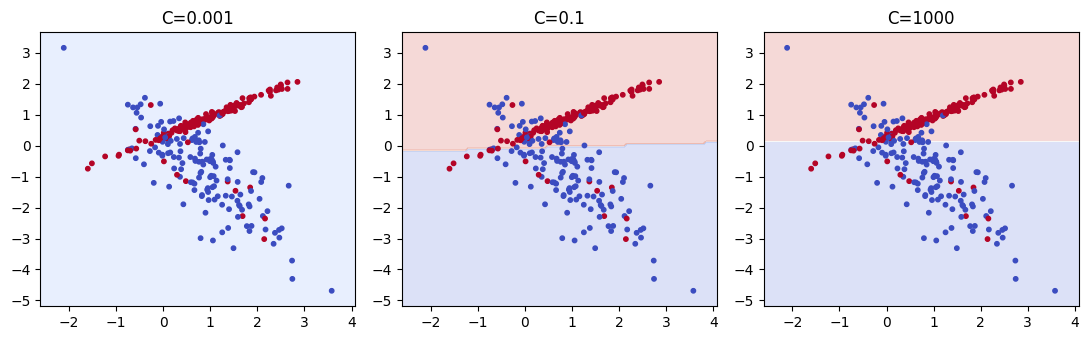

In [7]:
X2,y2=make_classification(n_samples=500,n_features=2,n_informative=2,n_redundant=0,n_clusters_per_class=1,class_sep=.8,flip_y=.08,random_state=42)
Xtr,Xtmp,ytr,ytmp=train_test_split(X2,y2,test_size=.4,random_state=42,stratify=y2);Xv,Xte,yv,yte=train_test_split(Xtmp,ytmp,test_size=.5,random_state=42,stratify=ytmp)
rows=[];mods={}
for c in [.001,.01,.1,1,10,100,1000]:
 p=pipe_svm(SVC(kernel='linear',C=c)).fit(Xtr,ytr);mods[c]=p;s=p.named_steps['svm'];z=p.named_steps['scale'].transform(Xtr);m=(2*ytr-1)*s.decision_function(z)
 rows.append({'C':c,'train acc':accuracy_score(ytr,p.predict(Xtr)),'val acc':accuracy_score(yv,p.predict(Xv)),'margin width':2/np.linalg.norm(s.coef_[0]),'SVs':len(s.support_),'violations':sum(m<1),'hinge loss':np.maximum(0,1-m).sum()})
tab=pd.DataFrame(rows).set_index('C');best=tab['val acc'].idxmax();print(tab.round(3).to_string());print('selected C',best,'test accuracy',accuracy_score(yte,mods[best].predict(Xte)))
fig,axs=plt.subplots(1,3,figsize=(11,3.5))
for ax,c in zip(axs,[.001,best,1000]):boundary(ax,mods[c],Xtr,ytr,f'C={c}')
plt.tight_layout();plt.show()

## 3. Tune C and gamma on noisy moons

Use 5-fold CV for an RBF SVM, visualize mean train and validation accuracy, and compare underfit, selected, and highly local models.

best {'svm__C': 10, 'svm__gamma': 1} test acc 0.9466666666666667
Underfit SVs 450 train 0.8533333333333334 test 0.8333333333333334
Selected SVs 82 train 0.9488888888888889 test 0.9466666666666667
Local SVs 386 train 1.0 test 0.9066666666666666


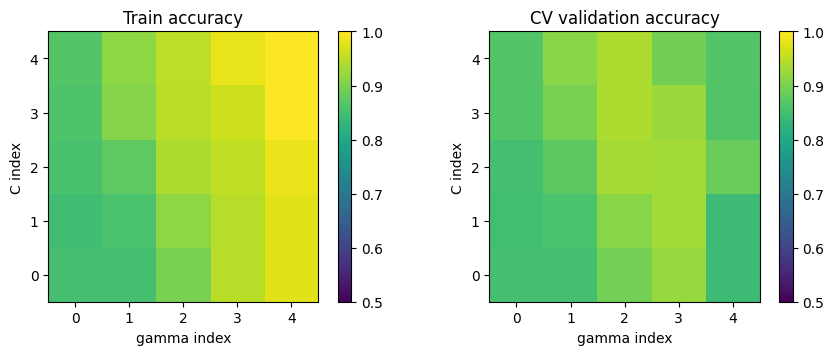

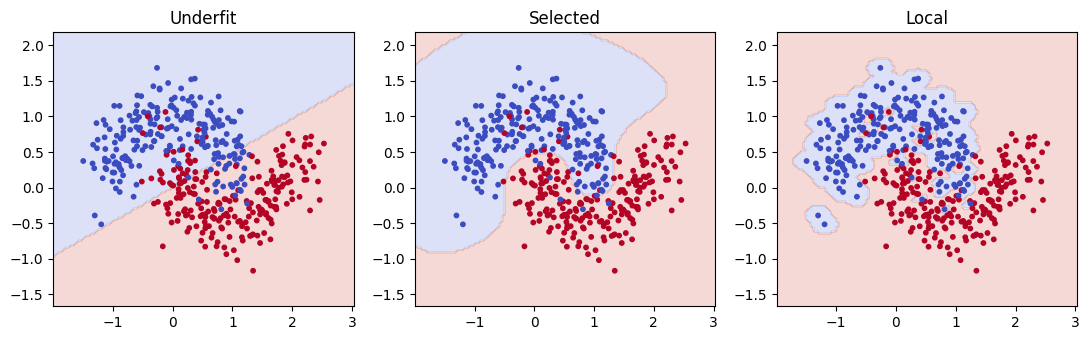

In [9]:
Xm,ym=make_moons(n_samples=600,noise=.25,random_state=42);Xmtr,Xmte,ymtr,ymte=train_test_split(Xm,ym,test_size=.25,random_state=42,stratify=ym)
search=GridSearchCV(pipe_svm(SVC(kernel='rbf')),{ 'svm__C':[.01,.1,1,10,100],'svm__gamma':[.01,.1,1,10,100]},cv=StratifiedKFold(5,shuffle=True,random_state=42),return_train_score=True,n_jobs=1).fit(Xmtr,ymtr)
tr=np.array(search.cv_results_['mean_train_score']).reshape(5,5);va=np.array(search.cv_results_['mean_test_score']).reshape(5,5)
fig,axs=plt.subplots(1,2,figsize=(9,3.5))
for ax,m,title in zip(axs,[tr,va],['Train accuracy','CV validation accuracy']):im=ax.imshow(m,origin='lower',vmin=.5,vmax=1);ax.set(title=title,xlabel='gamma index',ylabel='C index');fig.colorbar(im,ax=ax)
plt.tight_layout();plt.show();print('best',search.best_params_,'test acc',accuracy_score(ymte,search.predict(Xmte)))
fig,axs=plt.subplots(1,3,figsize=(11,3.5))
for ax,(title,c,g) in zip(axs,[('Underfit',.01,.01),('Selected',search.best_params_['svm__C'],search.best_params_['svm__gamma']),('Local',100,100)]):
 p=pipe_svm(SVC(kernel='rbf',C=c,gamma=g)).fit(Xmtr,ymtr);boundary(ax,p,Xmtr,ymtr,title);print(title,'SVs',len(p.named_steps['svm'].support_),'train',accuracy_score(ymtr,p.predict(Xmtr)),'test',accuracy_score(ymte,p.predict(Xmte)))
plt.tight_layout();plt.show()

## 4. Match kernels to data geometry

Compare linear, degree-2 polynomial, and RBF kernels on blobs, noisy XOR, and concentric circles. Tune C/gamma inside training data, then add x1*x2 as an explicit XOR feature.

   data kernel                                 params  test acc
  Blobs linear                        {'svm__C': 0.1}     1.000
  Blobs   poly        {'svm__C': 10, 'svm__gamma': 1}     0.440
  Blobs    rbf {'svm__C': 0.1, 'svm__gamma': 'scale'}     1.000
    XOR linear                         {'svm__C': 10}     0.568
    XOR   poly {'svm__C': 0.1, 'svm__gamma': 'scale'}     0.880
    XOR    rbf  {'svm__C': 10, 'svm__gamma': 'scale'}     0.872
Circles linear                        {'svm__C': 0.1}     0.568
Circles   poly         {'svm__C': 1, 'svm__gamma': 1}     1.000
Circles    rbf {'svm__C': 0.1, 'svm__gamma': 'scale'}     1.000
XOR x1*x2 engineered-feature test accuracy: 0.872 ; degree-2 kernel: 0.88


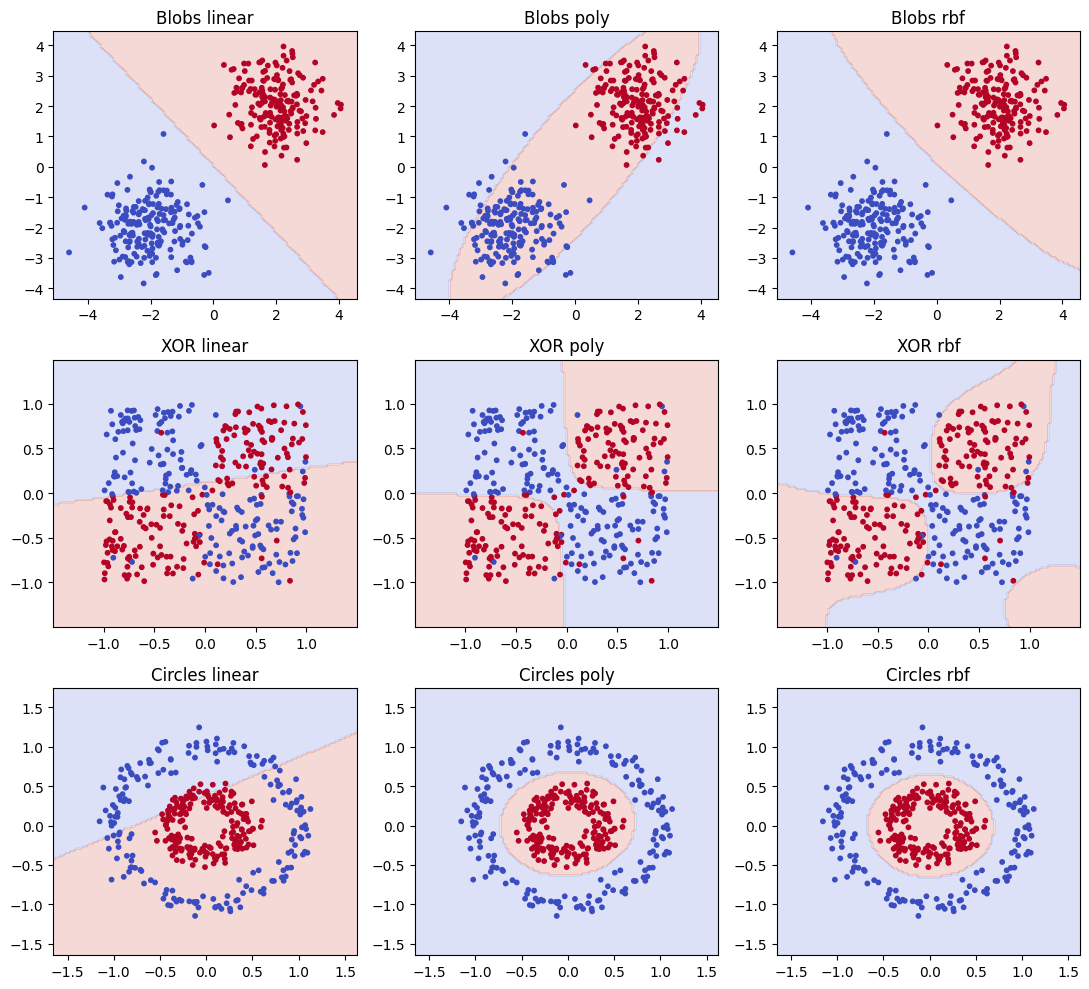

In [11]:
rng=np.random.default_rng(42);Xb,yb=make_blobs(n_samples=500,centers=[(-2,-2),(2,2)],cluster_std=.8,random_state=42)
Xx=rng.uniform(-1,1,(500,2));yx=(Xx[:,0]*Xx[:,1]>0).astype(int);flip=rng.choice(500,25,replace=False);yx[flip]=1-yx[flip]
Xc,yc=make_circles(n_samples=500,noise=.08,factor=.4,random_state=42);sets={'Blobs':(Xb,yb),'XOR':(Xx,yx),'Circles':(Xc,yc)}
rows=[];fig,axs=plt.subplots(3,3,figsize=(11,10));models={}
for i,(dn,(Xd,yd)) in enumerate(sets.items()):
 Xtr,Xte,ytr,yte=train_test_split(Xd,yd,test_size=.25,random_state=42,stratify=yd)
 for j,k in enumerate(['linear','poly','rbf']):
  grid={'svm__C':[.1,1,10]}
  if k!='linear':grid['svm__gamma']=['scale',.1,1]
  gs=GridSearchCV(pipe_svm(SVC(kernel=k,degree=2)),grid,cv=3,n_jobs=1).fit(Xtr,ytr);p=gs.best_estimator_;models[(dn,k)]=p;pred=p.predict(Xte)
  rows.append({'data':dn,'kernel':k,'params':gs.best_params_,'test acc':accuracy_score(yte,pred)});boundary(axs[i,j],p,Xtr,ytr,dn+' '+k)
plt.tight_layout();plt.show();print(pd.DataFrame(rows).round(3).to_string(index=False))
Xe=np.c_[Xx,Xx[:,0]*Xx[:,1]];Xe_tr,Xe_te,ye_tr,ye_te=train_test_split(Xe,yx,test_size=.25,random_state=42,stratify=yx)
eng=Pipeline([('scale',StandardScaler()),('svm',LinearSVC(max_iter=10000))]).fit(Xe_tr,ye_tr)
print('XOR x1*x2 engineered-feature test accuracy:',accuracy_score(ye_te,eng.predict(Xe_te)),'; degree-2 kernel:',rows[4]['test acc'])

## 5. Which points influence the boundary?
Compare a strictly non-support training point with support vectors, then move one support vector toward the opposing class.

chosen non-support distance: 1.232 ; chosen support distance: 0.594
         case               w      b  SVs
     baseline [0.858, -1.449] -0.090    3
remove non-SV [0.858, -1.449] -0.090    3
    remove SV [0.804, -1.359] -0.022    3
    SV move 0 [0.858, -1.449] -0.090    3
  SV move 0.5 [3.771, -6.372] -3.794    3
    SV move 1 [0.722, -1.367] -0.032    5
    SV move 2  [0.67, -1.345] -0.017    7


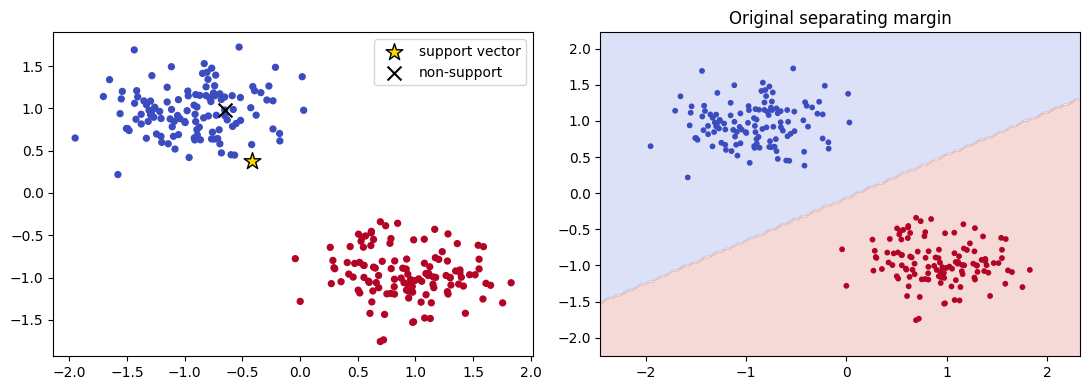

In [13]:
from sklearn.datasets import make_blobs
X,y=make_blobs(n_samples=240,centers=2,cluster_std=1.5,random_state=16); X=StandardScaler().fit_transform(X)
def fitlin(X,y): return SVC(kernel="linear",C=1e4).fit(X,y)
base=fitlin(X,y); d=base.decision_function(X); sv=base.support_[0]; nonsv=np.where(~np.isin(np.arange(len(y)),base.support_))[0][0]
rows=[]
for name,idx in [('baseline',None),('remove non-SV',nonsv),('remove SV',sv)]:
 keep=np.ones(len(y),bool)
 if idx is not None:keep[idx]=False
 m=fitlin(X[keep],y[keep]); rows.append({'case':name,'w':m.coef_[0].round(3),'b':round(m.intercept_[0],3),'SVs':len(m.support_)})
print('chosen non-support distance:',round(abs(d[nonsv])/np.linalg.norm(base.coef_),3),'; chosen support distance:',round(abs(d[sv])/np.linalg.norm(base.coef_),3))
for shift in [0,.5,1,2]:
 X2=X.copy(); X2[sv]+=shift*(X[y!=y[sv]].mean(axis=0)-X[sv]);m=fitlin(X2,y);rows.append({'case':f'SV move {shift}','w':m.coef_[0].round(3),'b':round(m.intercept_[0],3),'SVs':len(m.support_)})
print(pd.DataFrame(rows).to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(11,4)); ax[0].scatter(*X.T,c=y,cmap='coolwarm',s=18);ax[0].scatter(*X[sv],marker='*',s=160,c='gold',edgecolor='black',label='support vector');ax[0].scatter(*X[nonsv],marker='x',s=100,c='black',label='non-support');ax[0].legend();boundary(ax[1],base,X,y,'Original separating margin');plt.tight_layout();plt.show()

## 6. Scaling, tuning, and serving consistency
Large feature units can dominate the margin geometry. Fit preprocessing only on training data and reuse the fitted pipeline at prediction time.

In [15]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split,GridSearchCV
X,y=make_classification(n_samples=900,n_features=2,n_redundant=0,n_informative=2,n_clusters_per_class=2,class_sep=1.2,random_state=23); X[:,1]*=10000
Xa,Xte,ya,yte=train_test_split(X,y,test_size=.25,random_state=42,stratify=y);Xtr,Xv,ytr,yv=train_test_split(Xa,ya,test_size=.25,random_state=42,stratify=ya)
rows=[]
for scale in [False,True]:
 for k in ['linear','rbf']:
  p=pipe_svm(SVC(kernel=k,C=1,gamma=.1),scale).fit(Xtr,ytr);rows.append({'scale':scale,'kernel':k,'validation acc':accuracy_score(yv,p.predict(Xv))})
print(pd.DataFrame(rows).to_string(index=False))
for k,grid in [('linear',{'svm__C':[.01,.1,1,10,100]}),('rbf',{'svm__C':[.1,1,10,100],'svm__gamma':['scale',.001,.01,.1,1]})]:
 gs=GridSearchCV(pipe_svm(SVC(kernel=k),True),grid,cv=5,n_jobs=1).fit(Xtr,ytr);print(k,'CV',round(gs.best_score_,3),gs.best_params_,'holdout',round(accuracy_score(yte,gs.best_estimator_.predict(Xte)),3))
p=pipe_svm(SVC(kernel='rbf',C=1,gamma=.1),True).fit(Xtr,ytr);before=p.predict(Xte);wrong=Xte.copy();wrong[:,1]*=10000;after=p.predict(wrong);print('Serving with feature 2 multiplied again changes',np.mean(before!=after).round(3),'of predictions (deliberate preprocessing error).')

 scale kernel  validation acc
 False linear        0.934911
 False    rbf        0.668639
  True linear        0.934911
  True    rbf        0.928994
linear CV 0.962 {'svm__C': 1} holdout 0.964
rbf CV 0.966 {'svm__C': 10, 'svm__gamma': 'scale'} holdout 0.973
Serving with feature 2 multiplied again changes 0.462 of predictions (deliberate preprocessing error).


## 7. Rare defects: class weights and precisionâ€“recall
The validation set selects a weight using precision â‰¥ 0.15, then the untouched test set reports the selected model.

always-normal test recall: 0.0 ; prevalence: 0.035
{'weight': 'None', 'precision': 0.8, 'recall': 0.11764705882352941, 'F1': 0.20512820512820512, 'AP': 0.40770995541116545}
{'weight': 'balanced', 'precision': 0.18823529411764706, 'recall': 0.47058823529411764, 'F1': 0.2689075630252101, 'AP': 0.32839766712178503}
{'weight': '{0: 1, 1: 5}', 'precision': 0.5555555555555556, 'recall': 0.29411764705882354, 'F1': 0.38461538461538464, 'AP': 0.41907680884479426}
{'weight': '{0: 1, 1: 10}', 'precision': 0.4166666666666667, 'recall': 0.4411764705882353, 'F1': 0.42857142857142855, 'AP': 0.3968772685183372}
{'weight': '{0: 1, 1: 20}', 'precision': 0.25806451612903225, 'recall': 0.47058823529411764, 'F1': 0.3333333333333333, 'AP': 0.32366655716180925}
validation-selected: {'weight': 'balanced', 'precision': 0.18823529411764706, 'recall': 0.47058823529411764, 'F1': 0.2689075630252101, 'AP': 0.32839766712178503}
test precision/recall/F1/AP: 0.19444444444444445 0.6 0.2937062937062937 0.372702582604505

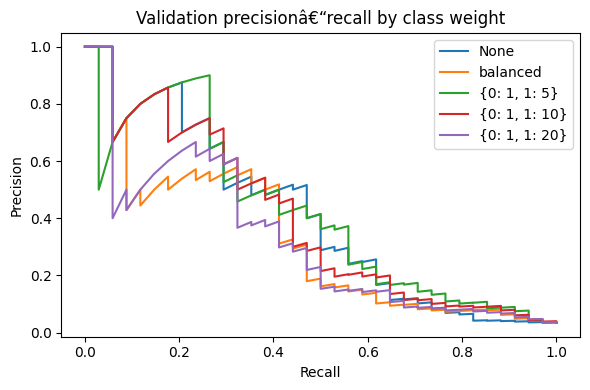

In [17]:
from sklearn.datasets import make_classification
from sklearn.metrics import precision_score,recall_score,f1_score,average_precision_score,precision_recall_curve,confusion_matrix
X,y=make_classification(n_samples=5000,n_features=12,n_informative=6,n_redundant=2,weights=[.97,.03],flip_y=.01,random_state=42)
Xa,Xte,ya,yte=train_test_split(X,y,test_size=.2,random_state=42,stratify=y);Xtr,Xv,ytr,yv=train_test_split(Xa,ya,test_size=.25,random_state=43,stratify=ya)
print('always-normal test recall:',recall_score(yte,np.zeros_like(yte)),'; prevalence:',round(y.mean(),3))
weights=[None,'balanced',{0:1,1:5},{0:1,1:10},{0:1,1:20}]; candidates=[]
for w in weights:
 p=pipe_svm(SVC(kernel='rbf',C=1,gamma='scale',class_weight=w),True).fit(Xtr,ytr);s=p.decision_function(Xv);pr=(s>=0).astype(int)
 row={'weight':str(w),'precision':precision_score(yv,pr,zero_division=0),'recall':recall_score(yv,pr),'F1':f1_score(yv,pr),'AP':average_precision_score(yv,s)};candidates.append((row,p));print(row)
elig=[x for x in candidates if x[0]['precision']>=.15];selected,p7=max(elig or candidates,key=lambda x:x[0]['recall']);print('validation-selected:',selected)
s7=p7.decision_function(Xte);print('test precision/recall/F1/AP:',precision_score(yte,s7>=0,zero_division=0),recall_score(yte,s7>=0),f1_score(yte,s7>=0),average_precision_score(yte,s7));print('confusion matrix (TN FP / FN TP):\n',confusion_matrix(yte,s7>=0))
fig,ax=plt.subplots(figsize=(6,4))
for row,_ in candidates:
 w=next(w for w in weights if str(w)==row['weight']);p=next(pp for rr,pp in candidates if rr is row);prec,rec,_=precision_recall_curve(yv,p.decision_function(Xv));ax.plot(rec,prec,label=str(w))
ax.set(xlabel='Recall',ylabel='Precision',title='Validation precisionâ€“recall by class weight');ax.legend();plt.tight_layout();plt.show()

## 8. Choose an inspection threshold under a cost and capacity limit
Costs are 500 per missed defect and 10 per false alarm. The line can inspect at most 8% of cases.

selected threshold/capacity/val cost: 0.3137712836294233 0.052 9360
test tuned: {'threshold': 0.3137712836294233, 'inspection_rate': 0.068, 'FN': 17, 'FP': 50, 'cost': 9000}
test default: {'threshold': 0, 'inspection_rate': 0.108, 'FN': 14, 'FP': 87, 'cost': 7870}


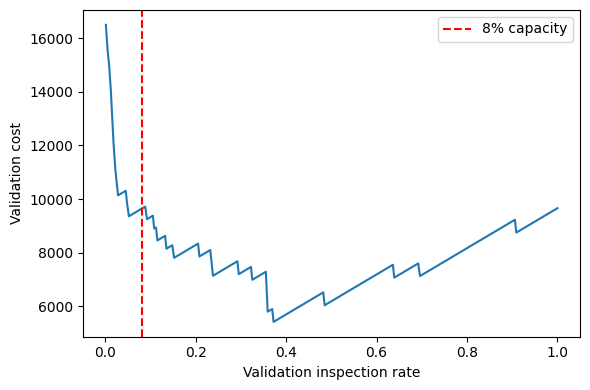

In [19]:
from sklearn.metrics import confusion_matrix
sv=p7.decision_function(Xv); thresholds=np.unique(np.quantile(sv,np.linspace(0,.999,300))); choices=[]
for t in thresholds:
 pred=sv>=t;tn,fp,fn,tp=confusion_matrix(yv,pred,labels=[0,1]).ravel();rate=pred.mean();choices.append((500*fn+10*fp,rate,t,fn,fp))
feasible=[z for z in choices if z[1]<=.08];best=min(feasible) if feasible else min(choices,key=lambda z:z[0]+1e7*max(z[1]-.08,0));t=best[2]
print('selected threshold/capacity/val cost:',t,best[1],best[0]);
def cost_report(y,s,t):
 tn,fp,fn,tp=confusion_matrix(y,s>=t,labels=[0,1]).ravel();return {'threshold':t,'inspection_rate':(s>=t).mean(),'FN':fn,'FP':fp,'cost':500*fn+10*fp}
print('test tuned:',cost_report(yte,p7.decision_function(Xte),t));print('test default:',cost_report(yte,p7.decision_function(Xte),0))
plt.figure(figsize=(6,4));plt.plot([z[1] for z in choices],[z[0] for z in choices]);plt.axvline(.08,color='red',ls='--',label='8% capacity');plt.xlabel('Validation inspection rate');plt.ylabel('Validation cost');plt.legend();plt.tight_layout();plt.show()

## 9. Calibrate SVM scores
An SVM decision value is not a probability. Fit a sigmoid to a separate calibration split and compare reliability and probability losses.

sigmoid raw score {'Brier': 0.061824654110746675, 'logloss': 0.2527109265727491, 'ROC AUC': 0.97729125619947, 'AP': 0.8845186231320713}
calibrated sigmoid {'Brier': 0.029283759402729873, 'logloss': 0.10470467653682572, 'ROC AUC': 0.97729125619947, 'AP': 0.8845186231320713}


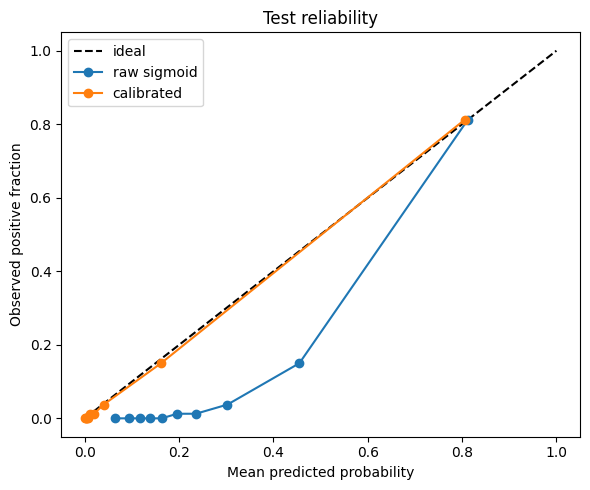

In [21]:
from sklearn.datasets import make_classification
from sklearn.metrics import brier_score_loss,log_loss,roc_auc_score,average_precision_score
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
X,y=make_classification(n_samples=4000,n_features=12,n_informative=7,weights=[.9,.1],random_state=17)
Xa,Xte,ya,yte=train_test_split(X,y,test_size=.2,random_state=42,stratify=y);Xtr,Xcal,ytr,ycal=train_test_split(Xa,ya,test_size=.25,random_state=42,stratify=ya)
calmodel=pipe_svm(SVC(kernel='rbf',C=2,gamma='scale',class_weight='balanced'),True).fit(Xtr,ytr);sc=calmodel.decision_function(Xcal);st=calmodel.decision_function(Xte);cal=LogisticRegression().fit(sc.reshape(-1,1),ycal);praw=1/(1+np.exp(-sc));prawt=1/(1+np.exp(-st));pc=cal.predict_proba(st.reshape(-1,1))[:,1]
for name,prob in [('sigmoid raw score',prawt),('calibrated sigmoid',pc)]:print(name,{'Brier':brier_score_loss(yte,prob),'logloss':log_loss(yte,prob),'ROC AUC':roc_auc_score(yte,prob),'AP':average_precision_score(yte,prob)})
fig,ax=plt.subplots(figsize=(6,5));ax.plot([0,1],[0,1],'k--',label='ideal')
for name,prob in [('raw sigmoid',prawt),('calibrated',pc)]:f,m=calibration_curve(yte,prob,n_bins=10,strategy='quantile');ax.plot(m,f,'o-',label=name)
ax.set(xlabel='Mean predicted probability',ylabel='Observed positive fraction',title='Test reliability');ax.legend();plt.tight_layout();plt.show()

## 10. One-class SVM: known faults and unseen safe regimes
Train only on healthy samples. A changed safe operating regime tests whether anomaly detection mistakes novelty for failure.

  nu  gamma  fault recall  known safe FAR  unseen safe FAR
0.01   0.05           1.0           0.007            0.993
0.01   0.10           1.0           0.007            0.983
0.01   0.50           1.0           0.040            0.993
0.05   0.05           1.0           0.067            0.997
0.05   0.10           1.0           0.063            0.997
0.05   0.50           1.0           0.060            0.997
0.10   0.05           1.0           0.110            1.000
0.10   0.10           1.0           0.113            1.000
0.10   0.50           1.0           0.137            1.000
selected {'nu': 0.01, 'gamma': 0.05, 'fault recall': 1.0, 'known safe FAR': 0.006666666666666667, 'unseen safe FAR': 0.9933333333333333}
unseen safe false alarm before / after representative regime added: 0.9933333333333333 0.2
fault detection recall after 5% training contamination: 0.37333333333333335


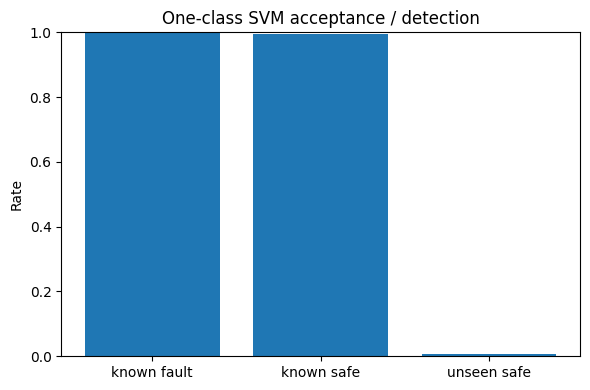

In [23]:
from sklearn.svm import OneClassSVM
rng=np.random.default_rng(202);normal=rng.normal(0,1,(1000,2));scale=StandardScaler().fit(normal);nt=scale.transform(normal)
known=rng.normal(0,1,(300,2));fault=rng.normal([4,4],.6,(300,2));unseen=rng.normal([-4,0],.6,(300,2))
rows=[]
for nu in [.01,.05,.1]:
 for g in [.05,.1,.5]:
  m=OneClassSVM(nu=nu,gamma=g).fit(nt);pred=m.predict(scale.transform(np.vstack([known,fault,unseen])))
  a,b,c=np.split(pred,3);rows.append({'nu':nu,'gamma':g,'fault recall':np.mean(b==-1),'known safe FAR':np.mean(a==-1),'unseen safe FAR':np.mean(c==-1),'model':m})
sel=max([r for r in rows if r['unseen safe FAR']<=.2] or rows,key=lambda r:r['fault recall']);print(pd.DataFrame([{k:v for k,v in r.items() if k!='model'} for r in rows]).round(3).to_string(index=False));print('selected', {k:v for k,v in sel.items() if k!='model'})
# Add a representative safe-regime sample to training, then re-evaluate that regime.
aug=np.vstack([normal,unseen[:100]]);sc2=StandardScaler().fit(aug);m2=OneClassSVM(nu=.05,gamma=.1).fit(sc2.transform(aug));print('unseen safe false alarm before / after representative regime added:',sel['unseen safe FAR'],np.mean(m2.predict(sc2.transform(unseen))==-1))
contam=np.vstack([normal,fault[:50]]);sc3=StandardScaler().fit(contam);m3=OneClassSVM(nu=.05,gamma=.1).fit(sc3.transform(contam));print('fault detection recall after 5% training contamination:',np.mean(m3.predict(sc3.transform(fault))==-1))
plt.figure(figsize=(6,4));plt.bar(['known fault','known safe','unseen safe'],[sel['fault recall'],1-sel['known safe FAR'],1-sel['unseen safe FAR']]);plt.ylim(0,1);plt.ylabel('Rate');plt.title('One-class SVM acceptance / detection');plt.tight_layout();plt.show()

## 11. SVR: epsilon, C, and support vectors
Compare validation error and support-vector count. The final model is evaluated once on the test split.

    C  epsilon  val MAE  val RMSE  SVs  epsilon-insensitive train loss
  0.1     0.01    0.441     0.520  296                           0.429
  0.1     0.10    0.441     0.518  272                           0.344
  0.1     0.30    0.443     0.523  191                           0.197
  0.1     0.60    0.459     0.542  101                           0.064
  1.0     0.01    0.304     0.356  295                           0.292
  1.0     0.10    0.301     0.354  248                           0.212
  1.0     0.30    0.315     0.375  162                           0.099
  1.0     0.60    0.382     0.453   58                           0.031
 10.0     0.01    0.185     0.233  284                           0.171
 10.0     0.10    0.187     0.234  201                           0.101
 10.0     0.30    0.202     0.249   62                           0.030
 10.0     0.60    0.273     0.332   25                           0.009
100.0     0.01    0.181     0.228  287                           0.164
100.0 

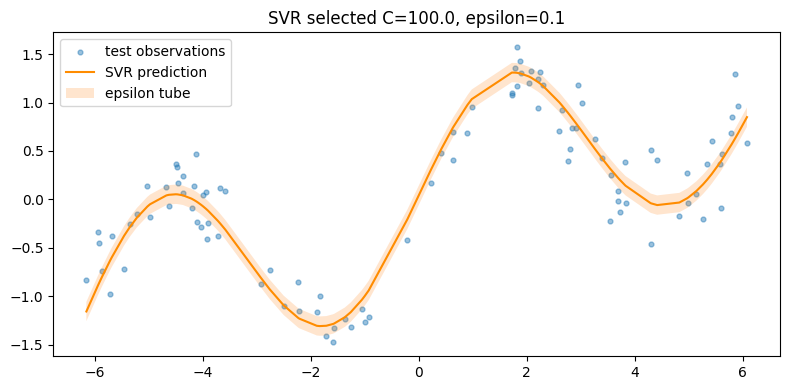

In [25]:
from sklearn.svm import SVR
rng=np.random.default_rng(72);x=np.linspace(-6,6,500);X=(x+rng.normal(0,.15,len(x))).reshape(-1,1);y=np.sin(x)+.2*x+rng.normal(0,.2,len(x))
Xa,Xte,ya,yte=train_test_split(X,y,test_size=.2,random_state=42);Xtr,Xv,ytr,yv=train_test_split(Xa,ya,test_size=.25,random_state=43)
rows=[];models_svr={}
for Cval in [.1,1,10,100]:
 for eps in [.01,.1,.3,.6]:
  sx=StandardScaler().fit(Xtr);a=sx.transform(Xtr);b=sx.transform(Xv);m=SVR(C=Cval,epsilon=eps,kernel='rbf',gamma=.5).fit(a,ytr);pred=m.predict(b);loss=np.maximum(0,np.abs(ytr-m.predict(a))-eps).mean();row={'C':Cval,'epsilon':eps,'val MAE':mean_absolute_error(yv,pred),'val RMSE':mean_squared_error(yv,pred)**.5,'SVs':len(m.support_),'epsilon-insensitive train loss':loss};rows.append(row);models_svr[(Cval,eps)]=(m,sx)
tab=pd.DataFrame(rows);print(tab.round(3).to_string(index=False));best=tab.loc[tab['val RMSE'].idxmin()];key=(best['C'],best['epsilon']);m,sx=models_svr[key];pt=m.predict(sx.transform(Xte));print('chosen',key,'test MAE/RMSE',mean_absolute_error(yte,pt),mean_squared_error(yte,pt)**.5)
fig,ax=plt.subplots(figsize=(8,4));order=np.argsort(Xte[:,0]);ax.scatter(Xte[:,0],yte,s=12,alpha=.45,label='test observations');ax.plot(Xte[order,0],pt[order],color='darkorange',label='SVR prediction');ax.fill_between(Xte[order,0],pt[order]-key[1],pt[order]+key[1],alpha=.2,label='epsilon tube');ax.set_title(f'SVR selected C={key[0]}, epsilon={key[1]}');ax.legend();plt.tight_layout();plt.show()
print('extrapolation x=12,14:',m.predict(sx.transform(np.array([[12.],[14.]]))))

## 12. Exact and approximate RBF SVMs
Compare accuracy, fit and prediction time, support-vector counts, and serialized model size on a 5,000-row nonlinear dataset.

In [27]:
from sklearn.datasets import make_moons
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
import time,pickle
X,y=make_moons(n_samples=5000,noise=.25,random_state=12);Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
configs=[('linear',Pipeline([('scale',StandardScaler()),('model',LinearSVC(C=1,max_iter=10000))]),{}),('exact RBF',Pipeline([('scale',StandardScaler()),('model',SVC(kernel='rbf'))]),{'model__C':[.1,1,10],'model__gamma':[.1,1,10]}),('NystrÃ¶m RBF',Pipeline([('scale',StandardScaler()),('map',Nystroem(kernel='rbf')) ,('model',LinearSVC(max_iter=10000))]),{'map__n_components':[100,300,600],'map__gamma':[.1,1],'model__C':[.1,1,10]})]
results=[]
for name,pipe,grid in configs:
 t0=time.perf_counter();gs=GridSearchCV(pipe,grid,cv=3,n_jobs=1).fit(Xtr,ytr);search=time.perf_counter()-t0;model=gs.best_estimator_;fit=[]
 for _ in range(3):t=time.perf_counter();model.fit(Xtr,ytr);fit.append(time.perf_counter()-t)
 pred=[]
 for _ in range(5):t=time.perf_counter();yp=model.predict(Xte);pred.append(time.perf_counter()-t)
 size=len(pickle.dumps(model))/1024**2;sv=len(model.named_steps['model'].support_) if hasattr(model.named_steps['model'],'support_') else None
 results.append({'method':name,'params':gs.best_params_,'CV search sec':round(search,2),'fit median sec':round(np.median(fit),4),'predict median sec':round(np.median(pred),4),'accuracy':accuracy_score(yte,yp),'F1':f1_score(yte,yp),'AP':average_precision_score(yte,model.decision_function(Xte)),'support vectors':sv,'serialized MB':round(size,3)})
print(pd.DataFrame(results).to_string(index=False))

      method                                                     params  CV search sec  fit median sec  predict median sec  accuracy       F1       AP  support vectors  serialized MB
      linear                                                         {}           0.07          0.0217              0.0005    0.8528 0.852800 0.932287              NaN          0.001
   exact RBF                        {'model__C': 1, 'model__gamma': 10}           7.76          0.3143              0.1090    0.9288 0.928514 0.938045            826.0          0.030
NystrÃ¶m RBF {'map__gamma': 1, 'map__n_components': 100, 'model__C': 1}          53.29          0.1823              0.0053    0.9296 0.929260 0.982316              NaN          0.080


# Integrated case study: batch-aware manufacturing defect screening
Synthetic 10,000-part data has 50 production batches, shifted sensor units, and rare defect labels. Entire batches are held out for validation and test to avoid leakage.

In [29]:
from sklearn.model_selection import GroupShuffleSplit
rng=np.random.default_rng(88);n=10000;groups=np.repeat(np.arange(50),200);X=rng.normal(size=(n,12));offset=rng.normal(0,.3,(50,12));X+=offset[groups]
z=X[:,:5];risk=z[:,0]*z[:,1]+.8*z[:,2]+.5*z[:,3]**2+rng.normal(0,.3,n);y=(risk>np.quantile(risk,.97)).astype(int);flip=rng.random(n)<.005;y[flip]=1-y[flip]
X[:,5]*=100;X[:,8]*=1000;X[:,10]*=10000
# 10 test batches, 8 validation batches, 32 training batches.
gss=GroupShuffleSplit(n_splits=1,test_size=10,random_state=42);itr,ite=next(gss.split(X,y,groups));gss=GroupShuffleSplit(n_splits=1,test_size=8,random_state=43);itr0,ivrel=next(gss.split(X[itr],y[itr],groups[itr]));iv=itr[ivrel];itr=itr[itr0]
# Downsample only the training fit for kernel runtime; validation/test remain complete batches.
rng=np.random.default_rng(89);fit_idx=itr
if len(itr)>4000:
 pos=itr[y[itr]==1];neg=itr[y[itr]==0];fit_idx=np.r_[rng.choice(pos,min(len(pos),1200),replace=False),rng.choice(neg,2800,replace=False)];rng.shuffle(fit_idx)
print('rows train/fit, validation, test:',len(itr),len(fit_idx),len(iv),len(ite),'; prevalence:',y.mean(),' batches:',len(set(groups[itr])),len(set(groups[iv])),len(set(groups[ite])))
models_batch={};scores=[]
for kernel in ['linear','poly','rbf']:
 m=Pipeline([('scale',StandardScaler()),('svm',SVC(kernel=kernel,C=1,degree=2,gamma='scale',class_weight='balanced'))]).fit(X[fit_idx],y[fit_idx]);sv=m.named_steps['svm'];s=m.decision_function(X[iv]);row={'kernel':kernel,'validation AP':average_precision_score(y[iv],s),'F1@0':f1_score(y[iv],s>=0),'SVs':len(sv.support_)};scores.append(row);models_batch[kernel]=m
print(pd.DataFrame(scores).to_string(index=False));chosen=max(scores,key=lambda r:r['validation AP'])['kernel'];model=models_batch[chosen];sv=model.decision_function(X[iv]);th=[]
for t in np.unique(np.quantile(sv,np.linspace(0,.999,300))):
 pred=sv>=t;tn,fp,fn,tp=confusion_matrix(y[iv],pred,labels=[0,1]).ravel();rate=pred.mean();th.append((500*fn+10*fp,rate,t,fn,fp))
feas=[a for a in th if a[1]<=.08];best=min(feas) if feas else min(th,key=lambda a:a[0]+1e7*max(a[1]-.08,0));threshold=best[2]
def batch_report(name,Xq,yq):
 s=model.decision_function(Xq);pred=s>=threshold;tn,fp,fn,tp=confusion_matrix(yq,pred,labels=[0,1]).ravel();return {'split':name,'precision':precision_score(yq,pred,zero_division=0),'recall':recall_score(yq,pred),'F1':f1_score(yq,pred),'AP':average_precision_score(yq,s),'inspection rate':pred.mean(),'cost per 1000':(500*fn+10*fp)/len(yq)*1000,'confusion TN/FP/FN/TP':(tn,fp,fn,tp)}
print('selected kernel/threshold:',chosen,threshold,'; validation cost/capacity:',best[0],best[1]);print(batch_report('held-out batches',X[ite],y[ite]))
# Stress test: new batches with stronger sensor offsets (SD 1.0).
ns=2000;Xs=rng.normal(size=(ns,12));gs=np.repeat(np.arange(10),200);Xs+=rng.normal(0,1.0,(10,12))[gs];zs=Xs[:,:5];rs=zs[:,0]*zs[:,1]+.8*zs[:,2]+.5*zs[:,3]**2+rng.normal(0,.3,ns);ys=(rs>np.quantile(rs,.97)).astype(int);fl=rng.random(ns)<.005;ys[fl]=1-ys[fl];Xs[:,5]*=100;Xs[:,8]*=1000;Xs[:,10]*=10000;print(batch_report('strong-shift stress',Xs,ys))

rows train/fit, validation, test: 6400 3015 1600 2000 ; prevalence: 0.0354  batches: 32 8 10
kernel  validation AP     F1@0  SVs
linear       0.112485 0.157025 2389
  poly       0.641473 0.427419  954
   rbf       0.534613 0.503067 1125
selected kernel/threshold: poly 0.40578288582349653 ; validation cost/capacity: 10290 0.078125
{'split': 'held-out batches', 'precision': 0.37333333333333335, 'recall': 0.7567567567567568, 'F1': 0.5, 'AP': 0.5342280746746016, 'inspection rate': 0.075, 'cost per 1000': 4970.0, 'confusion TN/FP/FN/TP': (1832, 94, 18, 56)}
{'split': 'strong-shift stress', 'precision': 0.12581344902386118, 'recall': 0.90625, 'F1': 0.22095238095238096, 'AP': 0.5988936956580574, 'inspection rate': 0.2305, 'cost per 1000': 3515.0, 'confusion TN/FP/FN/TP': (1533, 403, 6, 58)}
